### E-Commerce Review Intelligence System

**MBA Business Analytics Assignment**  
**Dataset:** Amazon Fine Food Reviews

This notebook develops an end-to-end review intelligence workflow that translates unstructured customer feedback into actionable product and customer-experience insights.

#### Business Problem

E-commerce leaders receive thousands of product reviews, but manually reading them does not scale. The business needs a reliable way to identify how customers feel, understand the themes behind that feedback, and prioritize products where negative experiences create the greatest commercial risk.

**Decision question:** Which products and customer-experience themes should management investigate first to protect customer satisfaction and future revenue?

#### Dataset Description

This analysis uses the **Amazon Fine Food Reviews dataset.** Each record contains a product identifier, a 1-5 star rating, a review summary, and the full review text. Ratings provide a practical sentiment proxy: scores 1-2 are negative, 3 is neutral, and 4-5 are positive.



| # | Column | Description |
|---:|---|---|
| 1 | `Id` | Unique row or review identifier |
| 2 | `ProductId` | Unique identifier for the food or gourmet product |
| 3 | `UserId` | Unique identifier for the reviewer |
| 4 | `ProfileName` | Name or nickname of the reviewer |
| 5 | `HelpfulnessNumerator` | Number of users who found the review helpful |
| 6 | `HelpfulnessDenominator` | Total number of votes on whether the review was helpful |
| 7 | `Score` | Star rating from 1 to 5 |
| 8 | `Time` | Timestamp of the review |
| 9 | `Summary` | Short text summary or title of the review |
| 10 | `Text` | Full text content of the customer review |



#### Proposed Solution

The proposed review intelligence system combines descriptive analytics and natural language processing. It will:

1. validate and prepare reviews for analysis;
2. translate ratings into three sentiment classes;
3. explore sentiment, rating, and review-length patterns;
4. train a TF-IDF and Logistic Regression baseline for explainable sentiment prediction;
5. discover recurring review themes using Latent Dirichlet Allocation (LDA); and
6. produce a product risk watchlist that managers can use to prioritize action.

#### Project Workflow and Deliverables
- **Input:** Raw customer reviews.
- **Explore the data:** Examine review ratings, sentiment distribution, missing values, and other relevant patterns.
- **Prepare the data:** Clean the reviews and create sentiment labels from star ratings.
- **Run three experiments:**
    1. **TF-IDF + Logistic Regression**
    2. **LSTM + Linear SVM**
    3. **Transformer + DistilBERT**
- **Evaluate and compare the models** using accuracy, macro F1, confusion matrices, and error analysis.
- **Select the best-performing model** and summarize sentiment results.
- **Discover review themes** using BERTopic, then relate topics to sentiment.
- **Translate findings into business insights** for product improvement, marketing, and service improvement.



### Common Use Cases

* Sentiment Analysis: Classifying reviews as positive, negative, or neutral using NLP models (such as logistic regression, LSTM, GRU, or transformer-based approaches).
* Text Summarization: Generating short, condensed versions of long customer feedback.
* Recommendation Systems: Analyzing user-product interactions and rating distributions.


In [119]:
# Review
#    ↓
# Cleaning
#    ↓
# TF-IDF
#    ↓
# Sparse numerical vector
#    ↓
# Logistic Regression
#    ↓
# Sentiment

In [3]:
#                     RAW REVIEWS
#                          │
#                          ▼
#               ┌────────────────────┐
#               │ Exploratory Data   │
#               │ Analysis           │
#               └─────────┬──────────┘
#                         │
#                         ▼
#              Cleaning + Label Creation
#                         │
#               ┌─────────┴──────────┐
#               │                    │
#               ▼                    ▼
#       CLASSICAL NLP           TRANSFORMER
#               │                    │
#            TF-IDF              Tokenizer
#           ┌───┴───┐                │
#           ▼       ▼                ▼
#      Logistic    Linear         DistilBERT
#      Regression   SVM               │
#           │       │                 │
#           └───────┴────────┬────────┘
#                            ▼
#                    MODEL EVALUATION
#                            │
#       ┌────────────────────┼──────────────────┐
#       ▼                    ▼                  ▼
#    Accuracy             Macro F1        Confusion Matrix
#                            │
#                            ▼
#                      ERROR ANALYSIS
#                            │
#                            ▼
#                       BEST MODEL
#                            │
#                            ▼
#                        BERTopic
#                            │
#                            ▼
#                 TOPIC × SENTIMENT
#                            │
#                            ▼
#                    BUSINESS INSIGHTS
#                            │
#                ┌───────────┼────────────┐
#                ▼           ▼            ▼
#              Product     Marketing     Service
#            Improvement    Insights    Improvement

1. Importing Libraries

In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

2. Importing Datasets

In [2]:
df = pd.read_csv("./Reviews.csv")

In [5]:
rows, cols = df.shape
print(f"Rows: {rows}, Columns: {cols}")


Rows: 568454, Columns: 10


3. Examining Dataset

In [6]:
df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [8]:
df.columns.tolist()

['Id',
 'ProductId',
 'UserId',
 'ProfileName',
 'HelpfulnessNumerator',
 'HelpfulnessDenominator',
 'Score',
 'Time',
 'Summary',
 'Text']

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 568454 entries, 0 to 568453
Data columns (total 10 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   Id                      568454 non-null  int64
 1   ProductId               568454 non-null  str  
 2   UserId                  568454 non-null  str  
 3   ProfileName             568428 non-null  str  
 4   HelpfulnessNumerator    568454 non-null  int64
 5   HelpfulnessDenominator  568454 non-null  int64
 6   Score                   568454 non-null  int64
 7   Time                    568454 non-null  int64
 8   Summary                 568427 non-null  str  
 9   Text                    568454 non-null  str  
dtypes: int64(5), str(5)
memory usage: 313.1 MB


In [10]:
df.isnull().sum()

Id                         0
ProductId                  0
UserId                     0
ProfileName               26
HelpfulnessNumerator       0
HelpfulnessDenominator     0
Score                      0
Time                       0
Summary                   27
Text                       0
dtype: int64

In [11]:
df["Score"].value_counts().sort_index()

Score
1     52268
2     29769
3     42640
4     80655
5    363122
Name: count, dtype: int64

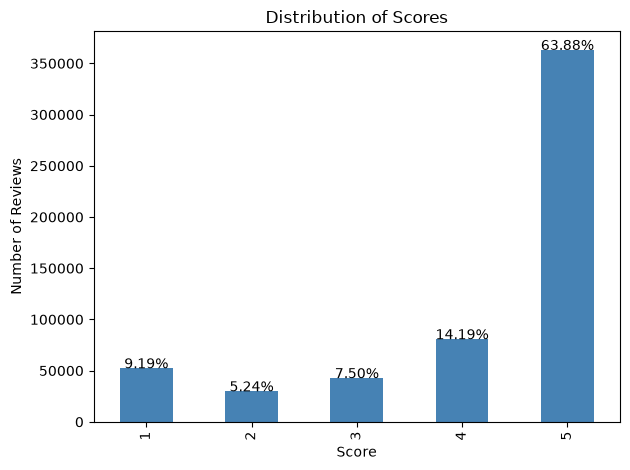

In [31]:
# Plot the distribution of review scores
df["Score"].value_counts().sort_index().plot(
    kind="bar",
    color="steelblue",
)

# Show percentage on the bars
total = len(df["Score"])
for p in plt.gca().patches:
    height = p.get_height()
    plt.gca().text(
        p.get_x() + p.get_width() / 2.,
        height,
        '{:.2f}%'.format(100 * height / total),
        ha="center"
    )

plt.title("Distribution of Scores")
plt.xlabel("Score")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

4. Convert Rating into Sentiment
* [1, 2] -> Negative
* [ 3  ]    -> Neutral
* [4, 5] -> Positive

In [15]:
def create_sentiment(score: int) -> str:
    if score <= 2:
        return "Negative"
    elif score == 3:
        return "Neutral"
    else:
        return "Positive"

In [16]:
df["Sentiment"] = df["Score"].apply(create_sentiment)

In [17]:
df[["Score", "Sentiment"]].head(10)

,Score,Sentiment
0,5,Positive
1,1,Negative
2,4,Positive
3,2,Negative
4,5,Positive
5,4,Positive
6,5,Positive
7,5,Positive
8,5,Positive
9,5,Positive


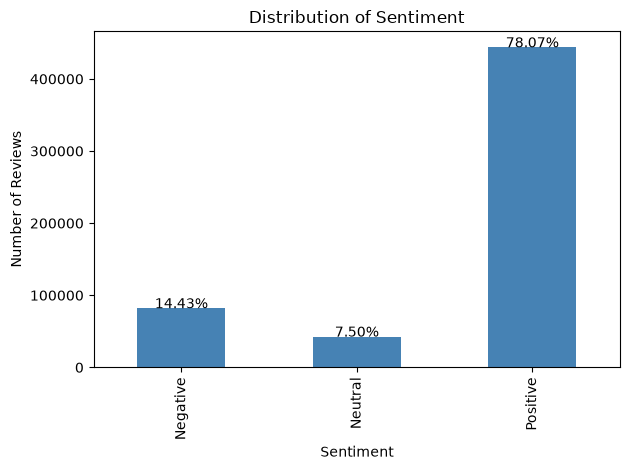

In [30]:
# Plot the distribution of Sentiment
df["Sentiment"].value_counts().sort_index().plot(
    kind="bar",
    color="steelblue",
)

# Show percentage on the bars
total = len(df["Sentiment"])
for p in plt.gca().patches:
    height = p.get_height()
    plt.gca().text(
        p.get_x() + p.get_width() / 2.,
        height,
        '{:.2f}%'.format(100 * height / total),
        ha="center"
    )


plt.title("Distribution of Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

Inference: Class Highly Imbalanced -
* Positive - 78 %
* Neutral - 7.5%
* Negative - 14.5 %

Missing Values

In [32]:
df["Summary"].isnull().sum()

np.int64(0)

In [35]:
df = df.dropna(subset=["Summary"])
df = df.reset_index(drop=True)

In [37]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 568427 entries, 0 to 568426
Data columns (total 11 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   Id                      568427 non-null  int64
 1   ProductId               568427 non-null  str  
 2   UserId                  568427 non-null  str  
 3   ProfileName             568401 non-null  str  
 4   HelpfulnessNumerator    568427 non-null  int64
 5   HelpfulnessDenominator  568427 non-null  int64
 6   Score                   568427 non-null  int64
 7   Time                    568427 non-null  int64
 8   Summary                 568427 non-null  str  
 9   Text                    568427 non-null  str  
 10  Sentiment               568427 non-null  str  
dtypes: int64(5), str(6)
memory usage: 322.0 MB


In [100]:
print("Total duplicated rows in the dataframe:", df.duplicated().sum())

Total duplicated rows in the dataframe: 0


In [101]:
print("Total duplicated ProductId count:", df["ProductId"].duplicated().sum())

Total duplicated ProductId count: 494169


> Inference: This means a lot of products has multiple reviews

In [109]:
df["ProductId"].unique().size
print("Unique Products count based on ProductID:", df["ProductId"].nunique())

Unique Products count based on ProductID: 74258


Top 10 Most Reviewed Products

In [104]:
top_10_products = df["ProductId"].value_counts().head(10)
print("Top 10 products based on ProductID count:")
print(top_10_products)

Top 10 products based on ProductID count:
ProductId
B007JFMH8M    913
B002QWP89S    632
B0026RQTGE    632
B002QWHJOU    632
B002QWP8H0    632
B003B3OOPA    623
B001EO5Q64    567
B0013NUGDE    564
B007M83302    564
B000VK8AVK    564
Name: count, dtype: int64


In [112]:
# No of Unique users review
print("No of Unique users Review's: ", df["UserId"].nunique())

No of Unique users Review's:  256056


In [118]:
# Top 10 users with most Reviews
top_users = df["UserId"].value_counts().head(10)
print("Top 10 users & their Review Counts: \n", top_users)

Top 10 users & their Review Counts: 
 UserId
A3OXHLG6DIBRW8    448
A1YUL9PCJR3JTY    421
AY12DBB0U420B     389
A281NPSIMI1C2R    365
A1Z54EM24Y40LL    256
A1TMAVN4CEM8U8    204
A2MUGFV2TDQ47K    201
A3TVZM3ZIXG8YW    199
A3PJZ8TU8FDQ1K    178
AQQLWCMRNDFGI     176
Name: count, dtype: int64


Merging Summary with Text in Review Column appended by comma(',')

In [40]:
df["Review"] = (df["Summary"].fillna("") + " , " + df["Text"].fillna(""))
df["Review"].head()

0    Good Quality Dog Food , I have bought several ...
1    Not as Advertised , Product arrived labeled as...
2    "Delight" says it all , This is a confection t...
3    Cough Medicine , If you are looking for the se...
4    Great taffy , Great taffy at a great price.  T...
Name: Review, dtype: str

5. Basic Text Preprocessing

In [41]:
import re

In [42]:
def clean_text(text: str) -> str:
    text = str(text).lower()

    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove URL's
    text = re.sub(r"http\S+|www\S+|https\S+", " ", text)

    # keep letters, numbers, apostrophes and spaces
    text = re.sub(r"[^a-z0-9'\s]", " ", text)

    # Remove repeated spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


In [43]:
df["Clean_Review"] = df["Review"].apply(clean_text)

In [46]:
print(df["Review"].iloc[-5])
print("----------")
print(df["Clean_Review"].iloc[-5])

Will not do without , Great for sesame chicken..this is a good if not better than resturants I have eaten at..My husband loved it..will find other recipes to use this in..
----------
will not do without great for sesame chicken this is a good if not better than resturants i have eaten at my husband loved it will find other recipes to use this in


* Inference : Stopwords should not be removed as it will remove the sentiment in the review comments

In [53]:
X = df["Clean_Review"]
y = df["Sentiment"]

6. Train / Validation / Test Split

* 70% training
* 15% validation
* 15% testing

Experiment 1: TF-IDF + Logistic Regression

In [54]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

In [55]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp # tries to preserve a similar sentiment distribution in the splits.
)

In [56]:
print("Training set size:", X_train.shape[0])
print("Validation set size:", X_val.shape[0])
print("Test set size:", X_test.shape[0])

Training set size: 397898
Validation set size: 85264
Test set size: 85265


#### 7. Applying TF-IDF Algorithm

> TFIDF(t,d)=TF(t,d)×IDF(t)

In [57]:
tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2), # use unigrams + bigrams
    min_df=2, # ignore terms appearing in fewer than 2 documents
    max_df=0.95, # ignore terms appearing in more than 95% of documents
    sublinear_tf=True # use sublinear term frequency scaling
)

In [59]:
X_train_tfidf = tfidf.fit_transform(X_train)

In [60]:
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

In [61]:
print(X_train_tfidf.shape)

(397898, 50000)


In [63]:
feature_names = tfidf.get_feature_names_out()
print(feature_names[:100])

['00' '00 and' '00 for' '00 per' '000' '01' '02' '03' '04' '05' '06' '07'
 '08' '09' '0g' '0g cholesterol' '0mg' '0mg sodium' '10' '10 00' '10 12'
 '10 15' '10 and' '10 calories' '10 count' '10 days' '10 for' '10 grams'
 '10 lb' '10 lbs' '10 min' '10 minutes' '10 month' '10 months' '10 of'
 '10 or' '10 ounce' '10 ounces' '10 oz' '10 pack' '10 per' '10 pound'
 '10 pounds' '10 seconds' '10 stars' '10 times' '10 to' '10 year'
 '10 years' '100' '100 arabica' '100 calorie' '100 calories' '100 count'
 '100 juice' '100 natural' '100 of' '100 organic' '100 percent' '100 pure'
 '100 tea' '100 whole' '1000' '108' '10g' '10oz' '10th' '11' '11 and'
 '11 grams' '11 month' '11 months' '11 ounce' '11 oz' '11 year' '11 years'
 '110' '110 calories' '11g' '12' '12 99' '12 and' '12 bags' '12 bottles'
 '12 boxes' '12 cans' '12 count' '12 cup' '12 for' '12 grams' '12 hours'
 '12 lb' '12 months' '12 of' '12 ounce' '12 ounces' '12 oz' '12 pack'
 '12 packages' '12 packs']


In [69]:
row = X_train_tfidf[0]
top_positions = row.data.argsort()[::-1][:15]

list(zip(
    feature_names[row.indices[top_positions]],
    row.data[top_positions]
))

[('gum', np.float64(0.21293067724423403)),
 ('really cool', np.float64(0.202183752519256)),
 ('back is', np.float64(0.20102010057795647)),
 ('draw back', np.float64(0.20035095906947517)),
 ('out quickly', np.float64(0.19635389555928)),
 ('great gum', np.float64(0.1944356591183641)),
 ('gum it', np.float64(0.18690986943137608)),
 ('battle', np.float64(0.18554291370236098)),
 ('fruit flavored', np.float64(0.1819900147839063)),
 ('wins', np.float64(0.18107403321918294)),
 ('quickly but', np.float64(0.18036832021810037)),
 ('burst of', np.float64(0.1758452682534734)),
 ('actually good', np.float64(0.17345143474071917)),
 ('draw', np.float64(0.1709584655473096)),
 ('runs out', np.float64(0.1708466610454004))]

8. Train Logistic Regression

* P(Sentiment ∣ TFIDF features)

In [64]:
model = LogisticRegression(
    max_iter=1000, # increase the maximum number of iterations for convergence
    class_weight='balanced',
    random_state=42
)

In [65]:
model.fit(X_train_tfidf, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default 

In [67]:
y_val_pred = model.predict(X_val_tfidf)
y_val_pred[:5]

array(['Negative', 'Positive', 'Negative', 'Positive', 'Positive'],
      dtype=object)

In [68]:
print(classification_report(y_val, y_val_pred))

              precision    recall  f1-score   support

    Negative       0.80      0.85      0.82     12302
     Neutral       0.45      0.74      0.56      6395
    Positive       0.98      0.91      0.94     66567

    accuracy                           0.89     85264
   macro avg       0.74      0.83      0.77     85264
weighted avg       0.92      0.89      0.90     85264



> The class distribution is imbalanced because positive reviews are more frequent than negative and neutral reviews. Therefore, Macro F1 is used alongside accuracy to evaluate performance fairly across all three sentiment classes.

Macro F1= 
(F1 
Negative
​
 +F1 
Neutral
​
 +F1 
Positive)/3
​
 
​


9. Final Test Evaluation

In [70]:
y_pred = model.predict(X_test_tfidf)

In [72]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average="macro"
)

recall = recall_score(
    y_test,
    y_pred,
    average="macro"
)

f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

print(f"Accuracy: {accuracy * 100:.2f}")
print(f"Precision: {precision * 100:.2f}")
print(f"Recall: {recall * 100:.2f}")
print(f"F1 Score: {f1 * 100:.2f}")

Accuracy: 88.72
Precision: 74.21
Recall: 83.34
F1 Score: 77.43


In [73]:
print(
    classification_report(
        y_test,
        y_pred,
        digits=4
    )
)

              precision    recall  f1-score   support

    Negative     0.7996    0.8479    0.8231     12302
     Neutral     0.4434    0.7441    0.5557      6396
    Positive     0.9833    0.9082    0.9443     66567

    accuracy                         0.8872     85265
   macro avg     0.7421    0.8334    0.7743     85265
weighted avg     0.9163    0.8872    0.8976     85265



10. Confusion Matrix

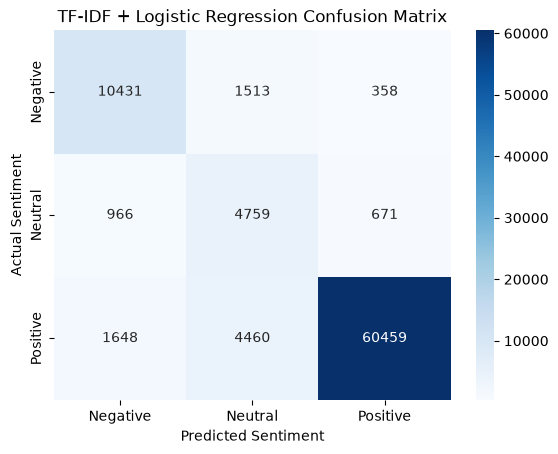

In [74]:
labels = ["Negative", "Neutral", "Positive"]

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=labels
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("TF-IDF + Logistic Regression Confusion Matrix")
plt.show()

In [76]:
results = pd.DataFrame({
    "Review": X_test,
    "Actual": y_test,
    "Predicted": y_pred
})

In [79]:
errors = results[
    results["Actual"] != results["Predicted"]
]

errors.head(20)

,Review,Actual,Predicted
217080,pero a caffeine substitute pero instant natura...,Positive,Neutral
353379,nutritional content it would be so helpful to ...,Positive,Neutral
422218,odd flavor there are plenty of tasty flavored ...,Negative,Neutral
527456,these are for dogs i should have realized it f...,Positive,Neutral
541615,too salty otherwise great if you're a saltohol...,Positive,Neutral
157624,product great price not so great why is the pr...,Positive,Neutral
28689,a lot of good quality need a lot of chive ring...,Positive,Neutral
896,break easily the first ball worked pretty well...,Negative,Neutral
418972,is it pure vanilla the ingredients are not lis...,Negative,Neutral
151371,not a fan of soy meatballs i really was lookin...,Negative,Neutral


In [81]:
# Feature maps for the top 20 words associated with each sentiment class
feature_names = np.array(
    tfidf.get_feature_names_out()
)

for i, sentiment in enumerate(model.classes_):
    top_indices = np.argsort(
        model.coef_[i]
    )[-20:]

    print("\n", sentiment)
    print(feature_names[top_indices])


 Negative
['disappointment' 'one star' 'very disappointed' 'not worth' 'tasteless'
 'disgusting' 'poor' 'not recommend' 'gross' 'nasty' 'disappointed'
 'disappointing' 'horrible' 'worst' 'awful' 'terrible' 'yuck' 'not'
 'two stars' 'not good']

 Neutral
['not my' 'dogs were' 'do feel' 'nothing special' 'not great' 'just ok'
 'meh' 'it three' 'alright' 'unfortunately' 'so so' 'decent' 'stars'
 'not bad' 'however' 'average' 'okay' 'ok' 'but' 'three stars']

 Positive
['favorite' 'hooked' 'happy' 'love' 'love this' 'fantastic'
 'be disappointed' 'love it' 'good' 'amazing' 'yum' 'wonderful' 'not too'
 'awesome' 'perfect' 'yummy' 'best' 'excellent' 'delicious' 'great']


In [82]:
from sklearn.dummy import DummyClassifier


In [83]:
dummy = DummyClassifier(
    strategy="most_frequent"
)


In [84]:

dummy.fit(X_train, y_train)

dummy_pred = dummy.predict(X_test_tfidf)


In [85]:
print(classification_report(
    y_test,
    dummy_pred,
    zero_division=0
))

              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00     12302
     Neutral       0.00      0.00      0.00      6396
    Positive       0.78      1.00      0.88     66567

    accuracy                           0.78     85265
   macro avg       0.26      0.33      0.29     85265
weighted avg       0.61      0.78      0.68     85265



Comparing Logistic Regression accuracy with Naive Model

In [90]:
print("Dummy Accuracy: %.2f%%" % (accuracy_score(y_test, dummy_pred)*100))
print("Logistic Accuracy: %.2f%%" % (accuracy*100))

Dummy Accuracy: 78.07%
Logistic Accuracy: 88.72%


In [ ]:
experiment_1_results = {
    "Model": "TF-IDF + Logistic Regression",
    "Accuracy": round(accuracy*100, 4),
    "Macro Precision": round(precision*100, 4),
    "Macro Recall": round(recall*100, 4),
    "Macro F1": round(f1*100, 4)
}

experiment_1_results